# Ordinary Least Squares and Ridge Regression: scikit-learn vs Moxie

**Reference examples:** `../scikit-learn/examples/linear_model/plot_ols_ridge.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/linear_model/plot_ols_ridge.html)), plus the pipelines
of `../scikit-learn/examples/linear_model/plot_polynomial_interpolation.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/linear_model/plot_polynomial_interpolation.html))
as the composition check, both at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:**
1. `LinearRegression` on one feature (BMI) of the bundled diabetes dataset, with the last 20 rows held out. The example reports MSE and R².
2. The OLS-versus-`Ridge(alpha=0.1)` variance demo: six noisy refits on two points, each predicting at `X_test = [[0], [2]]`, then a refit on the clean points.
3. Composition (from `plot_polynomial_interpolation.py`): `make_pipeline(PolynomialFeatures(d), Ridge(alpha=1e-3))` for d = 3, 4, 5, then `make_pipeline(SplineTransformer(n_knots=4, degree=3), Ridge(alpha=1e-3))`. After that come the 10-knot spline and the periodic spline with explicit knots.
4. Composition beyond the gallery: `cross_val_score` over `make_pipeline(StandardScaler(), Ridge())` on the full diabetes data, `GridSearchCV` over `Ridge.alpha`, and `clone` of a fitted Ridge.

**Adaptations:**
- The `np.random.seed(0)` noise draws of the variance demo are generated in Python and shared, so both sides fit identical inputs.
- MSE is computed in Python from Moxie's predictions; Moxie has no `metrics` module. R² comes from Moxie's own `score`.
- `cross_val_score`/`GridSearchCV` take model_selection's typed `CVAdapter`/`SearchAdapter` and scorer (documented model_selection adaptation, see #3). Folds are `KFold(5)` without shuffling on both sides.
- `Ridge` stores a length-one `intercept_` array where sklearn stores a scalar (documented linear_model adaptation).
- Plots are reduced in size (dpi 60).

**Determinism:** deterministic. The data is bundled or seeded, OLS and Ridge are closed-form solves, and the folds are unshuffled.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("linear_model/plot_ols_ridge")

## 1. scikit-learn (Python reference)

### Part 1: OLS on one diabetes feature (official code)

Mean squared error: 2548.07
Coefficient of determination: 0.47


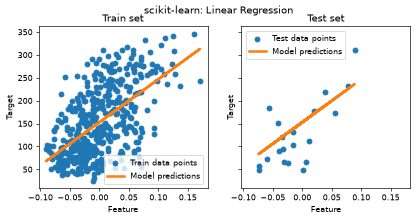

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X, y = load_diabetes(return_X_y=True)
X = X[:, [2]]  # Use only one feature
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=20, shuffle=False)
regressor = LinearRegression().fit(X_train, y_train)
y_pred = regressor.predict(X_test)
print(f"Mean squared error: {mean_squared_error(y_test, y_pred):.2f}")
print(f"Coefficient of determination: {r2_score(y_test, y_pred):.2f}")

fig, ax = plt.subplots(ncols=2, figsize=(8, 3.5), sharex=True, sharey=True, dpi=60)
ax[0].scatter(X_train, y_train, label="Train data points")
ax[0].plot(X_train, regressor.predict(X_train), linewidth=3, color="tab:orange", label="Model predictions")
ax[0].set(xlabel="Feature", ylabel="Target", title="Train set")
ax[0].legend()
ax[1].scatter(X_test, y_test, label="Test data points")
ax[1].plot(X_test, y_pred, linewidth=3, color="tab:orange", label="Model predictions")
ax[1].set(xlabel="Feature", ylabel="Target", title="Test set")
ax[1].legend()
fig.suptitle("scikit-learn: Linear Regression")
plt.show()
sk_ols = dict(coef=regressor.coef_, intercept=np.atleast_1d(regressor.intercept_), pred=y_pred,
              train_pred=regressor.predict(X_train), rank=regressor.rank_, singular=regressor.singular_,
              r2=r2_score(y_test, y_pred), mse=mean_squared_error(y_test, y_pred))
nb.share(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

### Part 2: OLS vs Ridge variance (official code; noise draws recorded for sharing)

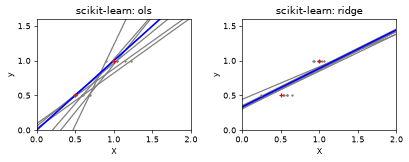

In [3]:
from sklearn import linear_model

X_train_small = np.c_[0.5, 1].T
y_train_small = [0.5, 1]
X_test_small = np.c_[0, 2].T
np.random.seed(0)
classifiers = dict(ols=linear_model.LinearRegression(), ridge=linear_model.Ridge(alpha=0.1))
draws, sk_lines = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), dpi=60)
for ax, (name, clf) in zip(axes, classifiers.items()):
    draws[name], sk_lines[name] = [], []
    for _ in range(6):
        this_X = 0.1 * np.random.normal(size=(2, 1)) + X_train_small
        draws[name].append(this_X)
        clf.fit(this_X, y_train_small)
        sk_lines[name].append(clf.predict(X_test_small))
        ax.plot(X_test_small, clf.predict(X_test_small), color="gray")
        ax.scatter(this_X, y_train_small, s=3, c="gray", marker="o", zorder=10)
    clf.fit(X_train_small, y_train_small)
    sk_lines[name].append(clf.predict(X_test_small))
    ax.plot(X_test_small, clf.predict(X_test_small), linewidth=2, color="blue")
    ax.scatter(X_train_small, y_train_small, s=30, c="red", marker="+", zorder=10)
    ax.set(title=f"scikit-learn: {name}", xlim=(0, 2), ylim=(0, 1.6), xlabel="X", ylabel="y")
fig.tight_layout()
plt.show()
sk_lines = {k: np.array(v) for k, v in sk_lines.items()}
nb.share(small_X=X_train_small, small_y=np.asarray(y_train_small, float), small_X_test=X_test_small,
         ols_draws=np.vstack(draws["ols"]), ridge_draws=np.vstack(draws["ridge"]))

### Part 3: pipelines from `plot_polynomial_interpolation.py` (official code)

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler
from sklearn.linear_model import Ridge


def f(x):
    return x * np.sin(x)


def g(x):
    return np.sin(x) - 0.7 * np.cos(x * 3)


x_plot = np.linspace(-1, 11, 100)
x_train = np.linspace(0, 10, 100)
rng = np.random.RandomState(0)
x_train = np.sort(rng.choice(x_train, size=20, replace=False))
y_train_f = f(x_train)
X_train_1d = x_train[:, np.newaxis]
X_plot = x_plot[:, np.newaxis]
sk_poly = {}
for degree in [3, 4, 5]:
    model = make_pipeline(PolynomialFeatures(degree), Ridge(alpha=1e-3))
    model.fit(X_train_1d, y_train_f)
    sk_poly[f"degree {degree}"] = model.predict(X_plot)
model = make_pipeline(SplineTransformer(n_knots=4, degree=3), Ridge(alpha=1e-3))
model.fit(X_train_1d, y_train_f)
sk_poly["B-spline"] = model.predict(X_plot)
sk_spline_coef = model[-1].coef_

y_train_g = g(x_train)
x_plot_ext = np.linspace(-1, 21, 200)
X_plot_ext = x_plot_ext[:, np.newaxis]
periodic_knots = np.linspace(0, 2 * np.pi, 10)[:, None]
sk_ext = {}
for transformer, label in [
    (SplineTransformer(degree=3, n_knots=10), "spline"),
    (SplineTransformer(degree=3, knots=periodic_knots, extrapolation="periodic"), "periodic spline"),
]:
    model = make_pipeline(transformer, Ridge(alpha=1e-3))
    model.fit(X_train_1d, y_train_g)
    sk_ext[label] = model.predict(X_plot_ext)
nb.share(x_train_1d=X_train_1d, y_train_f=y_train_f, y_train_g=y_train_g, X_plot=X_plot, X_plot_ext=X_plot_ext,
         periodic_knots=periodic_knots)

### Part 4: cross-validation, grid search and clone (beyond the gallery)

In [5]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

X_full, y_full = load_diabetes(return_X_y=True)
sk_cv = cross_val_score(make_pipeline(StandardScaler(), Ridge()), X_full, y_full, cv=KFold(5))
alphas = [0.001, 0.01, 0.1, 1.0, 10.0]
search = GridSearchCV(Ridge(), {"alpha": alphas}, cv=KFold(5)).fit(X_full, y_full)
sk_search = dict(mean=search.cv_results_["mean_test_score"], best_alpha=search.best_params_["alpha"],
                 best_score=search.best_score_, refit_coef=search.best_estimator_.coef_)
print("cross_val_score:", np.round(sk_cv, 4))
print("GridSearchCV best alpha:", sk_search["best_alpha"], "best score:", round(sk_search["best_score"], 4))
print("clone of a fitted Ridge is unfitted:", not hasattr(clone(Ridge().fit(X_full, y_full)), "coef_"))
nb.share(X_full=X_full, y_full=y_full, alphas=np.asarray(alphas))

cross_val_score: [0.428  0.5216 0.4856 0.4272 0.5486]
GridSearchCV best alpha: 0.001 best score: 0.4823
clone of a fitted Ridge is unfitted: True


## 2. Moxie (native Mojo)

Parts 1 and 2: `LinearRegression` and `Ridge` on the shared data.

In [6]:
%%mojo ols_ridge
from numojo import NDArray, Shape
from moxie.linear_model import LinearRegression, Ridge
from moxie_nb_io import load, save, save_floats, save_ints


def block(X: NDArray[DType.float64], start: Int, count: Int) raises -> NDArray[DType.float64]:
    var out = NDArray[DType.float64](Shape(count, X.shape[1]))
    for i in range(count * X.shape[1]):
        out.unsafe_set(i, X.unsafe_get(start * X.shape[1] + i))
    return out^


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var y_test = load("y_test")
    var regressor = LinearRegression()
    _ = regressor.fit(X_train, y_train)
    save("pred", regressor.predict(X_test))
    save("train_pred", regressor.predict(X_train))
    save("coef", regressor.coef_)
    save("intercept", regressor.intercept_)
    save("singular", regressor.singular_.value())
    save_ints("rank", [regressor.rank_.value()])
    save_floats("r2", [regressor.score(X_test, y_test)])

    # Variance demo: six noisy refits then the clean fit, predicting at X_test = [[0], [2]].
    var small_X = load("small_X")
    var small_y = load("small_y")
    var small_X_test = load("small_X_test")
    for name in ["ols", "ridge"]:
        var draws = load(String(name) + "_draws")
        var lines = NDArray[DType.float64](Shape(7, 2))
        var ols = LinearRegression()
        var ridge = Ridge(alpha=0.1)
        for r in range(7):
            var X = block(draws, 2 * r, 2) if r < 6 else small_X.copy()
            var line: NDArray[DType.float64]
            if String(name) == "ols":
                line = ols.fit(X, small_y).predict(small_X_test)
            else:
                line = ridge.fit(X, small_y).predict(small_X_test)
            lines.unsafe_set(2 * r, line.unsafe_get(0))
            lines.unsafe_set(2 * r + 1, line.unsafe_get(1))
        save(String(name) + "_lines", lines)
    print("rank_:", regressor.rank_.value(), " R2 on test:", regressor.score(X_test, y_test))

rank_: 1  R2 on test: 0.4725754479822716


Part 3: the same pipelines through `moxie.pipeline.make_pipeline`.

In [7]:
%%mojo pipelines
from moxie.linear_model import Ridge
from moxie.pipeline import make_pipeline
from moxie.preprocessing import PolynomialFeatures, SplineTransformer
from moxie_nb_io import load, save


def main() raises:
    var X_train = load("x_train_1d")
    var y_f = load("y_train_f")
    var y_g = load("y_train_g")
    var X_plot = load("X_plot")
    var X_plot_ext = load("X_plot_ext")
    for degree in [3, 4, 5]:
        var model = make_pipeline(PolynomialFeatures(degree), Ridge(alpha=1e-3))
        _ = model.fit(X_train, y_f)
        save("degree_" + String(degree), model.predict(X_plot))
    var spline = make_pipeline(SplineTransformer(n_knots=4, degree=3), Ridge(alpha=1e-3))
    _ = spline.fit(X_train, y_f)
    save("bspline", spline.predict(X_plot))
    save("bspline_coef", spline.estimator.coef_)
    var wide = make_pipeline(SplineTransformer(degree=3, n_knots=10), Ridge(alpha=1e-3))
    _ = wide.fit(X_train, y_g)
    save("spline_ext", wide.predict(X_plot_ext))
    var periodic = make_pipeline(
        SplineTransformer(degree=3, knots=load("periodic_knots"), extrapolation="periodic"), Ridge(alpha=1e-3))
    _ = periodic.fit(X_train, y_g)
    save("periodic_ext", periodic.predict(X_plot_ext))

Part 4: `cross_val_score` over a `StandardScaler` + `Ridge` pipeline, `GridSearchCV` over `Ridge.alpha`, and `clone`.

In [8]:
%%mojo cv_search
from numojo import NDArray
from std.utils import Variant
from moxie.base import SupervisedEstimator, Predictor, clone
from moxie.linear_model import Ridge
from moxie.model_selection import (GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer,
                                   cross_val_score)
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie.model_selection._split import _rows
from moxie.pipeline import Pipeline, make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save, save_floats

comptime Dense = NDArray[DType.float64]


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct R2[E: SupervisedEstimator & Predictor & Deinitable](TypedScorer):
    # The default regressor scorer (R2 of predict), as sklearn's estimator.score.
    comptime Estimator = Self.E
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: Self.E, X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        var prediction = rebind_var[Dense](estimator.predict(rebind[Self.E.Input](X)))
        var mean = Float64(0)
        for i in range(y.size):
            mean += y.unsafe_get(i)
        mean /= Float64(y.size)
        var residual = Float64(0)
        var total = Float64(0)
        for i in range(y.size):
            residual += (y.unsafe_get(i) - prediction.unsafe_get(i)) ** 2
            total += (y.unsafe_get(i) - mean) ** 2
        return 1 - residual / total


struct Rows[E: SupervisedEstimator & Predictor & Deinitable](CVAdapter):
    comptime Scorer = R2[Self.E]

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: Self.E, X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(rebind[Self.E.Input](X), rebind[Self.E.Target](y))


def cv_scores[E: SupervisedEstimator & Predictor & Deinitable](estimator: E, X: Dense, y: Dense) raises -> Dense:
    return cross_val_score[Rows[E]](estimator, X, y, Rows[E](), R2[E](), kfold(X.shape[0]), None, None)


struct RidgeR2(SearchScorer):
    comptime Estimator = Ridge[]
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: Ridge[], X: Dense, y: Dense, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X, y)


struct RidgeSearch(SearchAdapter):
    comptime Scorer = RidgeR2
    comptime Value = Float64

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return y.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: Ridge[], X: Dense, y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: Ridge[], params: Dict[String, Float64]) raises:
        for key in params.keys():
            if key != "alpha":
                raise Error("ValueError: this adapter tunes only alpha")
        _ = estimator.set_params(alpha=Optional(Variant[Float64, List[Float64]](params["alpha"])))

    def default_scorer(self) raises -> RidgeR2:
        return RidgeR2()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(y.shape[0])


def main() raises:
    var X = load("X_full")
    var y = load("y_full")
    var alphas = load("alphas")
    var pipe = make_pipeline(StandardScaler(), Ridge())
    save("cv_scores", cv_scores(pipe, X, y))

    var grid = Dict[String, List[Float64]]()
    var values = List[Float64]()
    for i in range(alphas.size):
        values.append(Float64(alphas.unsafe_get(i)))
    grid["alpha"] = values^
    var search = GridSearchCV[RidgeSearch](Ridge(), grid, RidgeSearch(), cv=kfold(X.shape[0]))
    search.fit(X, y, None, None)
    save("search_mean", search.cv_results_().mean_test_score)
    save_floats("search_best", [search.best_params_()["alpha"], search.best_score_()])
    save("search_coef", search.best_estimator_().coef_)

    var fitted = Ridge()
    _ = fitted.fit(X, y)
    var copy = clone(fitted)
    print("clone of a fitted Ridge is unfitted:", not copy.__sklearn_is_fitted__(),
          "| original still fitted:", fitted.__sklearn_is_fitted__())

clone of a fitted Ridge is unfitted: True | original still fitted: True


## 3. Side by side and parity

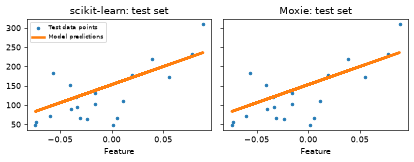

In [9]:
mx = nb.results["ols_ridge"]
moxie_nb.side_by_side(
    sklearn={"coef_": sk_ols["coef"], "intercept_": sk_ols["intercept"], "R2": [round(sk_ols["r2"], 4)],
             "MSE": [round(sk_ols["mse"], 2)]},
    moxie={"coef_": mx["coef"], "intercept_": mx["intercept"], "R2": [round(float(mx["r2"][0]), 4)],
           "MSE": [round(mean_squared_error(y_test, mx["pred"]), 2)]})
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), dpi=60, sharey=True)
for ax, (title, train_pred, pred) in zip(axes, [("scikit-learn", sk_ols["train_pred"], sk_ols["pred"]),
                                                ("Moxie", mx["train_pred"], mx["pred"])]):
    ax.scatter(X_test, y_test, s=10, label="Test data points")
    ax.plot(X_test, pred, linewidth=3, color="tab:orange", label="Model predictions")
    ax.set(title=f"{title}: test set", xlabel="Feature")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

DIRECT = ("Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); "
          "rounding differs only in factorization order, observed <1e-12 relative")
nb.compare("LinearRegression coef_", sk_ols["coef"], mx["coef"], rtol=1e-10, reason=DIRECT)
nb.compare("LinearRegression intercept_", sk_ols["intercept"], mx["intercept"], rtol=1e-10, reason=DIRECT)
nb.compare("LinearRegression rank_", sk_ols["rank"], mx["rank"][0], exact=True)
nb.compare("LinearRegression singular_", sk_ols["singular"], mx["singular"], rtol=1e-10, reason=DIRECT)
nb.compare("LinearRegression predict(X_test)", sk_ols["pred"], mx["pred"], rtol=1e-10, reason=DIRECT)
nb.compare("LinearRegression score (R2)", sk_ols["r2"], mx["r2"][0], rtol=1e-10, reason=DIRECT)
for name in ("ols", "ridge"):
    nb.compare(f"{name}: predictions at X_test for 6 noisy fits + clean fit", sk_lines[name],
               mx[f"{name}_lines"].reshape(7, 2), rtol=1e-10, atol=1e-12, reason=DIRECT)

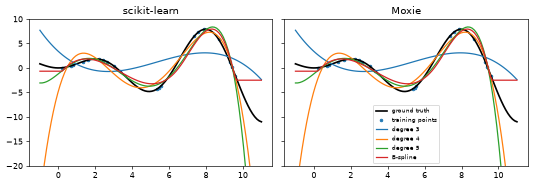

True

In [10]:
mp = nb.results["pipelines"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), dpi=60, sharey=True)
for ax, (title, preds) in zip(axes, [("scikit-learn", sk_poly), ("Moxie", {
        "degree 3": mp["degree_3"], "degree 4": mp["degree_4"], "degree 5": mp["degree_5"], "B-spline": mp["bspline"]})]):
    ax.plot(x_plot, f(x_plot), color="black", linewidth=2, label="ground truth")
    ax.scatter(x_train, y_train_f, s=10, label="training points")
    for label, pred in preds.items():
        ax.plot(x_plot, pred, label=label)
    ax.set(title=title, ylim=(-20, 10))
axes[1].legend(loc="lower center", fontsize=7); plt.tight_layout(); plt.show()
COND = ("Ridge(alpha=1e-3) on raw monomials of x in [0, 10] is ill-conditioned "
        "(cond(X^T X + alpha I) after centering: 1.9e9, 1.7e11, 1.5e13 for degrees 3, 4, 5), so Cholesky rounding "
        "is amplified; 1e-7 relative still matches every digit plotted")
for degree in (3, 4, 5):
    nb.compare(f"make_pipeline(PolynomialFeatures({degree}), Ridge(1e-3)).predict", sk_poly[f"degree {degree}"],
               mp[f"degree_{degree}"], rtol=1e-7, atol=1e-9, reason=COND)
nb.compare("make_pipeline(SplineTransformer(4, 3), Ridge(1e-3)).predict", sk_poly["B-spline"], mp["bspline"],
           rtol=1e-9, atol=1e-11, reason="well-conditioned B-spline basis; Float64 Cholesky rounding only")
nb.compare("  ... fitted Ridge step coef_", sk_spline_coef, mp["bspline_coef"], rtol=1e-9, atol=1e-11,
           reason="same as above")
nb.compare("make_pipeline(SplineTransformer(n_knots=10), Ridge(1e-3)).predict (extrapolated)", sk_ext["spline"],
           mp["spline_ext"], rtol=1e-9, atol=1e-11, reason="well-conditioned B-spline basis; Float64 Cholesky rounding only")
nb.compare("make_pipeline(SplineTransformer(periodic knots), Ridge(1e-3)).predict", sk_ext["periodic spline"],
           mp["periodic_ext"], rtol=1e-9, atol=1e-11, reason="well-conditioned periodic basis; Float64 Cholesky rounding only")

In [11]:
mc = nb.results["cv_search"]
moxie_nb.side_by_side(sklearn={"cross_val_score": np.round(sk_cv, 6), "grid mean_test_score": np.round(sk_search["mean"], 6)},
                      moxie={"cross_val_score": np.round(mc["cv_scores"], 6), "grid mean_test_score": np.round(mc["search_mean"][:, 0], 6)})
nb.compare("cross_val_score(make_pipeline(StandardScaler(), Ridge()), cv=KFold(5))", sk_cv, mc["cv_scores"],
           rtol=1e-10, reason="same folds; standardization + Float64 closed-form ridge per fold")
nb.compare("GridSearchCV(Ridge(), alpha grid).cv_results_['mean_test_score']", sk_search["mean"], mc["search_mean"][:, 0],
           rtol=1e-10, reason="same folds and closed-form fits")
nb.compare("GridSearchCV best alpha", sk_search["best_alpha"], mc["search_best"][0], exact=True)
nb.compare("GridSearchCV best_score_", sk_search["best_score"], mc["search_best"][1], rtol=1e-10, reason="as above")
nb.compare("GridSearchCV best_estimator_.coef_ (refit on all rows)", sk_search["refit_coef"], mc["search_coef"],
           rtol=1e-9, reason="Float64 closed-form refit")
nb.note("clone(fitted Ridge)", "PASS", "returns an unfitted copy; the original stays fitted (printed by the Mojo cell)")
nb.note("intercept_ of single-target models", "ADAPTED", "length-one array instead of a Python float (documented in families/linear_model/docs/scope.md)")
nb.note("cross_val_score / GridSearchCV", "ADAPTED", "typed CVAdapter/SearchAdapter and scorer structs (model_selection typed API, #3)")
nb.note("GridSearchCV mean_test_score layout", "ADAPTED", "(candidates, metrics) in Moxie; column 0 is compared "
        "(families/model_selection/algorithms/search/docs/search.md)")
nb.note("MSE", "ADAPTED", "computed in Python from Moxie's predictions; Moxie has no metrics module")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
LinearRegression coef_,PASS,"(1,)","(1,)",3.41e-13,3.64e-16,"rtol=1e-10, atol=0",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
LinearRegression intercept_,PASS,"(1,)","(1,)",0,0,"rtol=1e-10, atol=0",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
LinearRegression rank_,PASS,(),(),,,exact,0 mismatches,
LinearRegression singular_,PASS,"(1,)","(1,)",3.33e-16,3.41e-16,"rtol=1e-10, atol=0",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
LinearRegression predict(X_test),PASS,"(20,)","(20,)",2.84e-14,3.41e-16,"rtol=1e-10, atol=0",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
LinearRegression score (R2),PASS,(),(),1.11e-16,2.35e-16,"rtol=1e-10, atol=0",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
ols: predictions at X_test for 6 noisy fits + clean fit,PASS,"(7, 2)","(7, 2)",0,0,"rtol=1e-10, atol=1e-12",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
ridge: predictions at X_test for 6 noisy fits + clean fit,PASS,"(7, 2)","(7, 2)",2.22e-16,1.62e-16,"rtol=1e-10, atol=1e-12",,"Float64 closed-form solves on both sides (SciPy LAPACK lstsq/cholesky vs Moxie's SVD/Cholesky); rounding differs only in factorization order, observed <1e-12 relative"
"make_pipeline(PolynomialFeatures(3), Ridge(1e-3)).predict",PASS,"(100,)","(100,)",5.52e-13,2.5e-12,"rtol=1e-07, atol=1e-09",,"Ridge(alpha=1e-3) on raw monomials of x in [0, 10] is ill-conditioned (cond(X^T X + alpha I) after centering: 1.9e9, 1.7e11, 1.5e13 for degrees 3, 4, 5), so Cholesky rounding is amplified; 1e-7 relative still matches every digit plotted"
"make_pipeline(PolynomialFeatures(4), Ridge(1e-3)).predict",PASS,"(100,)","(100,)",1.44e-10,1.4e-09,"rtol=1e-07, atol=1e-09",,"Ridge(alpha=1e-3) on raw monomials of x in [0, 10] is ill-conditioned (cond(X^T X + alpha I) after centering: 1.9e9, 1.7e11, 1.5e13 for degrees 3, 4, 5), so Cholesky rounding is amplified; 1e-7 relative still matches every digit plotted"
